In [36]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score


results = {}

In [64]:
# helpers
def evaluate(y_true,y_pred):
    mae = mean_absolute_error(y_true,y_pred)
    rmse = root_mean_squared_error(y_true,y_pred)
    r2 = r2_score(y_true,y_pred)
    return mae, rmse, r2

# Mean Baseline
Taking the mean of both the cl and cd and using that as the prediction

In [ ]:
# Load the CSV data into dataframe
CSV_PATH = Path().resolve().parent/"data"/"processed"/"airfrans_coefficients.csv"
df = pd.read_csv(CSV_PATH)


# Split dataframe into train and test data
train_df = df.loc[df["split_full"]=="train"]
test_df = df.loc[df["split_full"]=="test"]

# Get mean cl and cd value from training data
mean_cl = train_df["cl"].mean()
mean_cd = train_df["cd"].mean()

print(f"Mean cl from training data: {mean_cl}")
print(f"Mean cd from training data: {mean_cd}")

# Predict the values by solely taking the mean
cl_pred = np.full(len(test_df),mean_cl)
cd_pred = np.full(len(test_df),mean_cd)

# Scoreing the prediction
cl_mae, cl_rmse, cl_r2 = evaluate(test_df["cl"],cl_pred)
cd_mae, cd_rmse, cd_r2 = evaluate(test_df["cd"],cd_pred)

# Outputs
print("\n--- Cl (coefficient of Lift) ---")
print(f"MAE: {cl_mae}")
print(f"RMSE: {cl_rmse}")
print(f"R^2: {cl_r2}")

print("--- Cd (coefficient of Drag) ---")
print(f"MAE: {cd_mae}")
print(f"RMSE: {cd_rmse}")
print(f"R^2: {cd_r2}")

# add to the results
results["mean_baseline"] = {"cl_mae":cl_mae,"cl_rmse":cl_rmse,"cl_r2":cl_r2,"cd_mae":cd_mae,"cd_rmse":cd_rmse,"cd_r2":cd_r2}

Mean cl from training data: 0.6767168151116846
Mean cd from training data: 0.012495524718604436

--- Cl (coefficient of Lift) ---
MAE: 0.4982478689429241
RMSE: 0.579817991426866
R^2: -0.0020055116225636826
--- Cd (coefficient of Drag) ---
MAE: 0.0034340043936832883
RMSE: 0.004728631989820384
R^2: -0.0011017976425085063


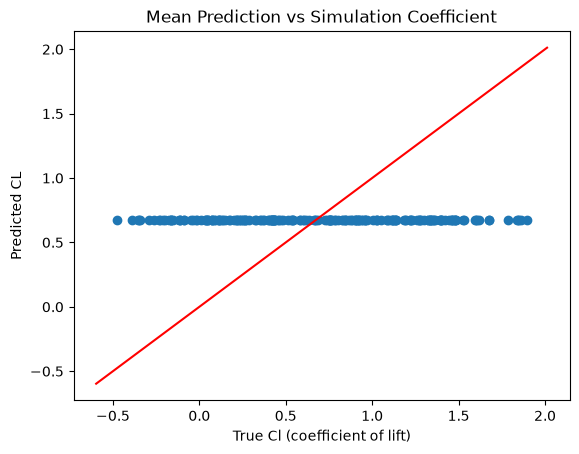

In [59]:
# Visualisation of the pred cl vs true
fig, ax = plt.subplots()

# Scatter of predicted vs true
ax.scatter(test_df["cl"],cl_pred)

# plot y=x as ideal line
lims = [np.min([ax.get_xlim(),ax.get_ylim()]),np.max([ax.get_xlim(),ax.get_ylim()])]
ax.plot(lims, lims,c="red")

ax.set_title("Mean Prediction vs Simulation Coefficient")
ax.set_ylabel("Predicted CL")
ax.set_xlabel("True Cl (coefficient of lift)")
plt.show()

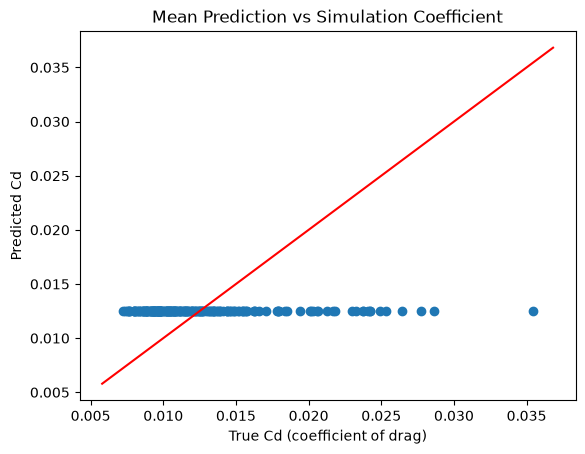

In [60]:
# Visualisation of the pred cd vs true
fig, ax = plt.subplots()

# Scatter of predicted vs true
ax.scatter(test_df["cd"],cd_pred)

# plot y=x as ideal line
lims = [np.min([ax.get_xlim(),ax.get_ylim()]),np.max([ax.get_xlim(),ax.get_ylim()])]
ax.plot(lims, lims,c="red")

ax.set_title("Mean Prediction vs Simulation Coefficient")
ax.set_ylabel("Predicted Cd")
ax.set_xlabel("True Cd (coefficient of drag)")
plt.show()

In [61]:
print(results)

{'mean_baseline': {'cl_mae': 0.4982478689429241, 'cl_rmse': 0.579817991426866, 'cl_r2': -0.0020055116225636826, 'cd_mae': 0.0034340043936832883, 'cd_rmse': 0.004728631989820384, 'cd_r2': -0.0011017976425085063}}


# Thin-Airfoil Theory

$Cl = 2\pi \times (\alpha-\alpha_{lo})$

Assumptions:
- The airfoil is very thin: airfoil is treated as just its camber line
- The angle of attack is small
- the air has no viscosity
- The flow leaves the sharp trailing edge smoothly


In [ ]:
cl_pred = 2*np.pi * np.deg2rad(test_df["angleOfAttack"])

cl_mae, cl_rmse, cl_r2 = evaluate(test_df["cl"],cl_pred)

print("\n--- Cl (coefficient of Lift) ---")
print(f"MAE: {cl_mae}")
print(f"RMSE: {cl_rmse}")
print(f"R^2: {cl_r2}")

results["thin_airfoil_theory"] = {"cl_mae":cl_mae,"cl_rmse":cl_rmse,"cl_r2":cl_r2}


--- Cl (coefficient of Lift) ---
MAE: 0.4982478689429241
RMSE: 0.29375180477444884
R^2: 0.7428137043370256


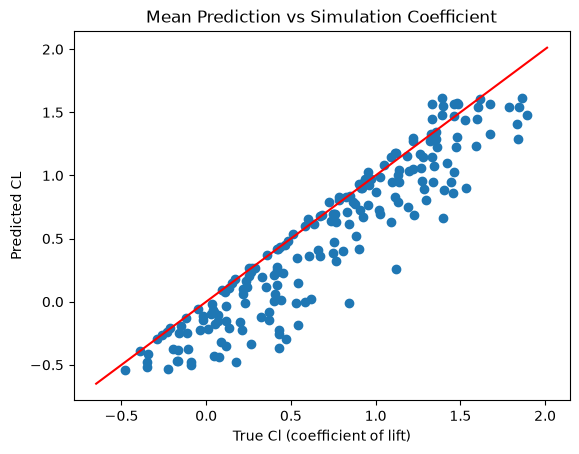

In [70]:
# Visualisation of thin-Airfoil Theory
fig, ax = plt.subplots()

# Scatter of predicted vs true
ax.scatter(test_df["cl"],cl_pred)

# plot y=x as ideal line
lims = [np.min([ax.get_xlim(),ax.get_ylim()]),np.max([ax.get_xlim(),ax.get_ylim()])]
ax.plot(lims, lims,c="red")

ax.set_title("Mean Prediction vs Simulation Coefficient")
ax.set_ylabel("Predicted CL")
ax.set_xlabel("True Cl (coefficient of lift)")
plt.show()

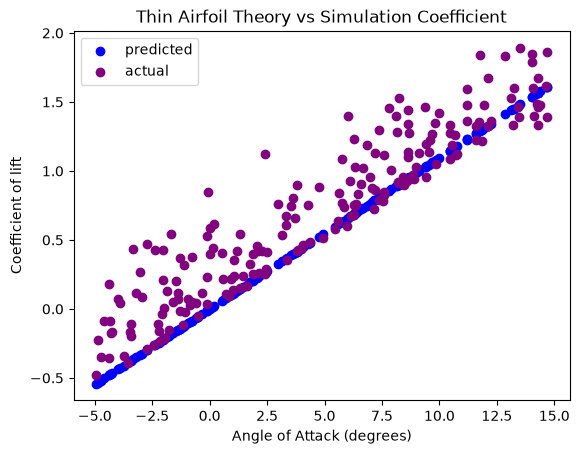

In [78]:
# visualisation of thin-airfoil theory against angle of attack
fig, ax = plt.subplots()

# Scatter of predicted vs true
ax.scatter(test_df["angleOfAttack"],cl_pred, c="Blue", label="predicted")
ax.scatter(test_df["angleOfAttack"],test_df["cl"],c="Purple", label="actual")

# plot y=x as ideal line
# lims = [np.min([ax.get_xlim(),ax.get_ylim()]),np.max([ax.get_xlim(),ax.get_ylim()])]
#ax.plot(lims, lims,c="red")

ax.set_title("Thin Airfoil Theory vs Simulation Coefficient")
ax.set_ylabel("Coefficient of lift")
ax.set_xlabel("Angle of Attack (degrees)")
ax.legend()
plt.show()